# xStocks dividend gap: three hedge strategies

This notebook measures the price risk between the dividend **ex-date** and the **payment date** of xStocks. It compares three strategies that remove this risk:

- **A.** Short-term financing: borrow cash and buy the shares before the ex-date.
- **B.** Long futures: buy futures on the shares and close them on the payment date.
- **C.** Call options: buy at-the-money calls that expire on or after the payment date.

**Scope.** The data covers the 10 xStocks with the largest underlying market cap and the dividend events of the last 6 months. `fetch_data.py` sets this scope (`--top-market-cap 10 --months 6`).

The notebook holds the numbers. The legal context (issuer, custodians, venue regulation) is in [`doc/legal/`](doc/legal/README.md). The data comes from [`fetch_data.py`](fetch_data.py). See the [README](README.md) for setup.

All venue values were checked on **2026-10-19**. Each value has a status:

| Status | Meaning |
|---|---|
| CONFIRMED | The venue or a regulator publishes the value. |
| UNCONFIRMED | Only a secondary source gives the value. Check it before you use it. |
| ESTIMATE | The research calculated the value from similar products. |
| ASSUMPTION | No source exists. The value is a placeholder. Change it when you know the real value. |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import norm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

DATA = Path("data")
AS_OF = "2026-10-19"
WHT = 0.30            # US withholding tax on dividends for most xStocks events
S_REF = 250.0         # reference share price (USD) to turn per-contract fees into a fraction of X

events = pd.read_csv(DATA / "xstocks_dividend_events.csv",
                     parse_dates=["ex_date", "pay_date", "record_date", "p_prev_date", "p_pay_date"])
rates = pd.read_csv(DATA / "rates.csv", parse_dates=["date"], index_col="date")
universe_file = DATA / "universe.csv"
universe = pd.read_csv(universe_file) if universe_file.exists() else None
SOFR_NOW = rates["sofr"].dropna().iloc[-1]
EFFR_NOW = rates["effr"].dropna().iloc[-1]

# Chart style: reference categorical palette (dataviz skill), thin marks, recessive grid.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948",
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["grid"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "axes.grid": True, "axes.axisbelow": True, "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": C["ink"],
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110, "lines.linewidth": 2,
})
print(f"events: {len(events)}   SOFR {SOFR_NOW:.2f}%   EFFR {EFFR_NOW:.2f}%   (latest NY Fed values)")

events: 14   SOFR 3.88%   EFFR 3.88%   (latest NY Fed values)


## 1. Problem

A cash dividend does not go to xStocks holders as cash. The issuer reinvests the dividend into more shares and increases the token **multiplier**. The multiplier step is:

$$\text{step} = \frac{D \cdot (1 - w)}{P_{\text{ref}}}$$

$D$ is the gross dividend per share, $w$ is the withholding tax rate, and $P_{\text{ref}}$ is a reference close price.

The issuer changed the time of the multiplier update in about **May 2026**:

| Period | Multiplier update | Reference price | Cash arrives | Price risk for the issuer |
|---|---|---|---|---|
| Before May 2026 | Evening of the **payment date** | Close on the payment date | Payment date | None. The issuer buys at the same price that sets the multiplier. |
| From May 2026 | Evening **before the ex-date** | Close before the ex-date | Payment date | Yes, for the full gap. |

```
 close before ex-date      ex-date                                   payment date
        |                     |                                           |
  P_prev sets the        holders see the                        custodian receives the cash.
  multiplier.            new balance.                           Issuer buys the shares at P_pay.
        |<------------------- issuer is short the new shares ------------>|
```

The issuer must buy $\Delta N = N \cdot D (1-w) / P_{\text{prev}}$ shares. It receives the cash $X = N \cdot D (1-w)$ on the payment date. If the price goes up, $X$ buys fewer shares than the multiplier promised. The loss is:

$$\text{Loss} = X \cdot \left(\frac{P_{\text{pay}}}{P_{\text{prev}}} - 1\right)$$

The evidence for the timing change is in section 2.2. The legal background is in [`doc/legal/xstocks-ecosystem.md`](doc/legal/xstocks-ecosystem.md).

## 2. Data

### 2.1 Coverage

`fetch_data.py` joins three sources:

1. The xStocks API gives the events, multipliers, and dividend amounts.
2. Nasdaq or stockanalysis.com gives the ex-date and payment date.
3. Yahoo Finance gives the close prices.

The first table shows the selected xStocks. Some of them pay no dividend, so they have no events. Events that the script cannot match are in `data/unmatched_events.csv`.

In [2]:
if universe is not None:
    n_events = events.groupby("xstock").size()
    display(universe.assign(market_cap_bn=universe["market_cap_usd"] / 1e9,
                            events=universe["xstock"].map(n_events).fillna(0).astype(int))
            [["rank", "xstock", "company", "market_cap_bn", "events"]]
            .style.format({"market_cap_bn": "{:,.0f}"}).hide(axis="index")
            .set_caption("Universe: largest underlying market cap (Nasdaq screener, USD bn)"))

coverage = pd.concat({
    "activation basis": events["activation_basis"].value_counts(),
    "dates source": events["dates_source"].value_counts(),
    "amount check": events["match"].value_counts(),
}).rename("events").to_frame()
display(coverage)

unmatched_file = DATA / "unmatched_events.csv"
if unmatched_file.exists():
    unmatched = pd.read_csv(unmatched_file)
    display(unmatched["match"].value_counts().rename("unmatched events").to_frame())

usable = events.dropna(subset=["p_prev", "p_pay", "gap_days"]).query("gap_days > 0").copy()
usable["T_eff"] = (usable["pay_date"] - usable["p_prev_date"]).dt.days
print(f"usable events (prices on both dates): {len(usable)} of {len(events)},",
      f"{usable['underlying'].nunique()} underlyings, ex-dates {usable['ex_date'].min():%Y-%m-%d} to {usable['ex_date'].max():%Y-%m-%d}")
display(usable.groupby("underlying")["wht_rate"].first().rename("withholding rate (API)").to_frame().T)

rank,xstock,company,market_cap_bn,events
1,NVDAx,NVIDIA Corporation,"5,161",2
2,AAPLx,Apple Inc.,"5,013",2
3,GOOGLx,Alphabet Inc.,"4,165",2
4,MSFTx,Microsoft Corporation,"3,928",2
5,AMZNx,Amazon.com Inc.,"2,697",0
6,TSMx,Taiwan Semiconductor Manufacturing Company Ltd.,"2,140",2
7,SPCXx,Space Exploration Technologies Corp.,"1,982",0
8,METAx,Meta Platforms Inc.,"1,807",2
9,AVGOx,Broadcom Inc.,"1,569",2
10,TSLAx,Tesla Inc.,"1,401",0


events
activation basis ex-date            14
dates source     nasdaq             12
                 stockanalysis       2
amount check     ok                 14

usable events (prices on both dates): 14 of 14, 7 underlyings, ex-dates 2026-05-11 to 2026-09-21


underlying,AAPL,AVGO,GOOGL,META,MSFT,NVDA,TSM
withholding rate (API),0.3,0.3,0.3,0.3,0.3,0.3,0


### 2.2 Check of the multiplier rule

The multiplier step gives the reference price that the issuer used: `implied_ref_price = net dividend / step`. The table compares it with the close before the ex-date ($P_{\text{prev}}$) and the close on the payment date ($P_{\text{pay}}$). A match within 0.1% shows which close the issuer used.

All events in the 6-month window use the new rule (update before the ex-date). The evidence for the old rule (update on the payment date) comes from older events. See [`doc/legal/xstocks-ecosystem.md`](doc/legal/xstocks-ecosystem.md#activation-time-three-sources-disagree). TSM pays its dividend in TWD. The USD amount in the xStocks API differs a little from the amount at the date source, so the TSM reference price can differ by up to 0.3%.

In [3]:
chk = events.dropna(subset=["implied_ref_price", "p_prev"]).copy()
chk["matches_P_prev"] = (chk["implied_ref_price"] / chk["p_prev"] - 1).abs() < 0.001
chk["matches_P_pay"] = (chk["implied_ref_price"] / chk["p_pay"] - 1).abs() < 0.001
display(chk.groupby("activation_basis")[["matches_P_prev", "matches_P_pay"]].mean()
        .map(lambda v: f"{v:.0%}").rename(columns=lambda c: c.replace("_", " ")))

by_month = (events.assign(month=pd.to_datetime(events["effective_time_utc"]).dt.to_period("M"))
            .pivot_table(index="month", columns="activation_basis", values="event_id", aggfunc="count", fill_value=0))
display(by_month.tail(18))

,matches P prev,matches P pay
activation_basis,,
ex-date,93%,0%


activation_basis,ex-date
month,
2026-05,2
2026-06,5
2026-08,2
2026-09,5


### 2.3 Gap length T

$T$ is the number of calendar days from the ex-date to the payment date. The hedge starts one trading day earlier, at the close before the ex-date. The backtest in section 5 uses this longer period ($T_{\text{eff}}$, from the close before the ex-date to the payment date).

,count,mean,std,min,10%,25%,50%,75%,90%,max
gap_days,14,13.71,8.334,3,4.2,7.25,10,21,22,28
T_eff,14,15.79,7.402,6,7.2,10.25,12.5,22,23,29
gap_trading_days,14,9.5,5.446,3,3.6,5,7,14.75,15.7,18


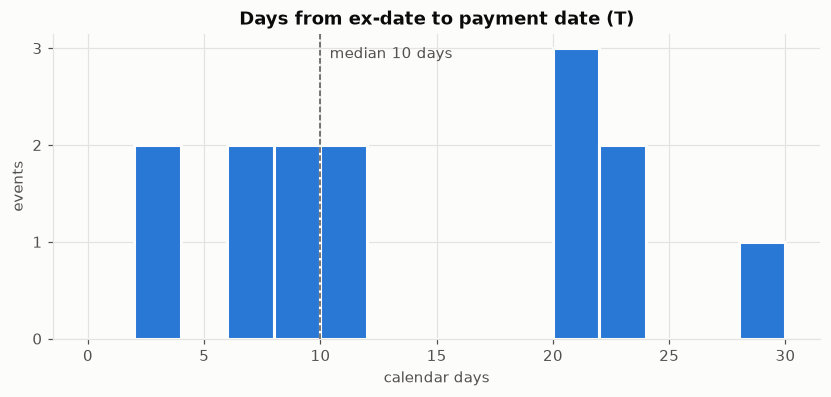

In [4]:
display(usable[["gap_days", "T_eff", "gap_trading_days"]].describe(percentiles=[.1, .25, .5, .75, .9]).T)

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, min(usable["gap_days"].max(), 70) + 3, 2)
ax.hist(usable["gap_days"].clip(upper=bins[-1] - 1), bins=bins, color=C["blue"], edgecolor=C["surface"], linewidth=2)
ax.set_title("Days from ex-date to payment date (T)")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("calendar days")
ax.set_ylabel("events")
ax.axvline(usable["gap_days"].median(), color=C["ink2"], linewidth=1, linestyle="--")
ax.annotate(f"median {usable['gap_days'].median():.0f} days", (usable["gap_days"].median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=C["ink2"])
plt.show()

### 2.4 Price change in the gap

The unhedged loss, as a fraction of $X$, is $P_{\text{pay}} / P_{\text{prev}} - 1$. A positive value is a loss for the issuer. The chart shows each event against $T_{\text{eff}}$. The shaded band is ±1 standard deviation for a stock with the median volatility, $\pm\sigma\sqrt{T_{\text{eff}}/365}$. The table lists the events with a loss, largest first.

The price change includes the ex-dividend drop ($-D/P_{\text{prev}}$). This drop is a gain for the issuer and for every strategy. Section 5 shows it as a separate column.

price change in bps of X (14 events):  min: -1035   median: 94   max: 1069
share of events with a loss (price up): 57%


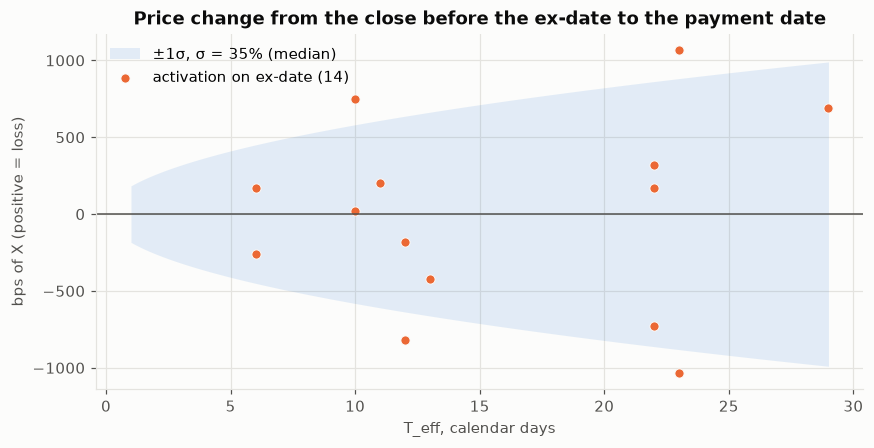

,xstock,ex_date,pay_date,T_eff,div_gross_api,p_prev,p_pay,px_change_bps
11,TSMx,2026-09-16,2026-10-08,23,0.875,413.75,457.99,1069
13,METAx,2026-09-21,2026-09-28,10,0.525,665.75,715.62,749
4,TSMx,2026-06-11,2026-07-09,29,0.751,408.75,436.96,690
10,NVDAx,2026-09-10,2026-10-01,22,0.250,223.67,230.86,321
9,GOOGLx,2026-09-04,2026-09-14,11,0.220,342.48,349.39,202
8,MSFTx,2026-08-20,2026-09-10,22,0.910,484.31,492.44,168
0,AAPLx,2026-05-11,2026-05-14,6,0.270,293.32,298.21,167
3,GOOGLx,2026-06-08,2026-06-15,10,0.220,368.53,369.35,22


In [5]:
usable["px_change_bps"] = usable["px_change"] * 1e4
q = usable["px_change_bps"].agg(["min", "median", "max"])
print(f"price change in bps of X ({len(usable)} events):  min: {q['min']:.0f}   median: {q['median']:.0f}   max: {q['max']:.0f}")
print(f"share of events with a loss (price up): {(usable['px_change'] > 0).mean():.0%}")

sigma_med = usable["vol_20d"].median()
t = np.linspace(1, max(usable["T_eff"].max(), 10), 200)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(t, -sigma_med * np.sqrt(t / 365) * 1e4, sigma_med * np.sqrt(t / 365) * 1e4,
                color=C["blue"], alpha=0.12, linewidth=0, label=f"±1σ, σ = {sigma_med:.0%} (median)")
for basis, color in (("ex-date", C["orange"]), ("payment-date", C["blue"]), ("other", C["aqua"])):
    sub = usable[usable["activation_basis"] == basis]
    if len(sub):
        ax.scatter(sub["T_eff"], sub["px_change_bps"], s=36, color=color, edgecolor=C["surface"], linewidth=0.6,
                   label=f"activation on {basis} ({len(sub)})")
ax.axhline(0, color=C["ink2"], linewidth=1)
ax.set_title("Price change from the close before the ex-date to the payment date")
ax.set_xlabel("T_eff, calendar days")
ax.set_ylabel("bps of X (positive = loss)")
ax.legend(loc="upper left")
plt.show()

worst = usable[usable["px_change"] > 0].nlargest(10, "px_change")[["xstock", "ex_date", "pay_date", "T_eff", "div_gross_api", "p_prev", "p_pay", "px_change_bps"]]
display(worst.style.format({"ex_date": "{:%Y-%m-%d}", "pay_date": "{:%Y-%m-%d}", "p_prev": "{:.2f}", "p_pay": "{:.2f}",
                            "px_change_bps": "{:.0f}", "div_gross_api": "{:.3f}"}).set_caption(f"{len(worst)} events with a loss for the issuer, largest first"))

## 3. Formulas

### Inputs

| Symbol | Meaning | Unit |
|---|---|---|
| $N$ | Number of underlying shares that back the tokens of one xStock | shares |
| $D$ | Gross dividend per share | USD |
| $T$ | Calendar days from the ex-date to the payment date | days |

### Constants and venue parameters

| Symbol | Meaning | Source |
|---|---|---|
| $w$ | Withholding tax rate. Use 0.30 for most US stocks. | xStocks API `withholdingTaxRate` |
| $r_A$ | Annual loan rate of the venue | Section 4.1 |
| $r_B$ | Annual financing rate in the futures price | Section 4.2 |
| $f_B$, $f_C$ | Round-trip fees as a fraction of $X$ | Sections 4.2 and 4.3 |
| $\sigma$ | Annual volatility of the stock | Section 4.3 |

### Amount to reinvest

$$X = N \cdot D \cdot (1 - w)$$

### Cost of each strategy

| Strategy | Formula | What the issuer does |
|---|---|---|
| **A. Financing** | $\text{Cost}_A = X \cdot r_A \cdot \dfrac{T}{360}$ | Borrow $X$ before the ex-date. Buy the shares. Pay back the loan with the dividend cash. |
| **B. Long futures** | $\text{Cost}_B = X \cdot \left(r_B \cdot \dfrac{T}{360} + f_B\right)$ | Buy futures on $X$ of shares before the ex-date. Sell the futures and buy the shares on the payment date. |
| **C. Call options** | $\text{Cost}_C = X \cdot \left(0.4 \cdot \sigma \cdot \sqrt{\dfrac{T}{365}} + f_C\right)$ | Buy at-the-money calls on $X$ of shares. Sell the calls and buy the shares on the payment date. |

### Notes

1. **A and B** lock the price. The cost is the same in every scenario.
2. **C** is the option premium. It is the maximum cost. If the price goes down, the issuer keeps the gain.
3. $0.4 \cdot \sigma \cdot \sqrt{T/365}$ is the standard approximation of an at-the-money option price, as a fraction of the share price ($0.4 \approx 1/\sqrt{2\pi}$).
4. The formulas use $T$ from the ex-date. A real hedge starts at the close before the ex-date. Add 1 to 3 days for a weekend.
5. The formulas leave out bid-ask spreads and the dividend that the new shares can receive. Both are small compared with the costs above.

In [6]:
def x_amount(N, D, w=WHT):
    "USD that the issuer must reinvest."
    return N * D * (1 - w)

def cost_a(N, D, T, r_a):
    "Strategy A. r_a: annual loan rate (0.05 = 5%)."
    return x_amount(N, D) * r_a * T / 360

def cost_b(N, D, T, r_b, f_b):
    "Strategy B. r_b: annual financing in the futures price. f_b: round-trip fees as a fraction of X."
    return x_amount(N, D) * (r_b * T / 360 + f_b)

def cost_c(N, D, T, sigma, f_c):
    "Strategy C. sigma: annual volatility. f_c: round-trip fees as a fraction of X."
    return x_amount(N, D) * (0.4 * sigma * np.sqrt(T / 365) + f_c)

## 4. Venues and parameter values

The venue list comes from the legal filter in [`doc/legal/README.md`](doc/legal/README.md#how-the-venues-were-filtered). The **Status** column of each venue is one of:

- **kept**: the issuer can use the venue.
- **conditional**: the issuer can use the venue only after a legal check.
- **reference**: the venue is too expensive. The table shows it for comparison only.
- **excluded**: the venue does not accept the issuer. The table shows it for comparison only.

The tables keep only venues whose values are **CONFIRMED**. Section 9 lists the other venues (UNCONFIRMED, ESTIMATE, or ASSUMPTION). They are not in the backtest or the result.

Rates use the latest NY Fed values (SOFR, EFFR) from `data/rates.csv`. The backtest in section 5 uses the rate on each event date instead.

### 4.1 Strategy A: short-term financing

**Description.** On the trading day before the ex-date, the issuer borrows $X$ in USD. It buys $\Delta N$ shares at the close ($P_{\text{prev}}$). On the payment date, the custodian receives the dividend cash. The issuer pays back the loan with this cash and pays the interest.

**Risk.** None for the price. The loan must have collateral. The xStocks underlying shares are pledged to the token holders, so the issuer cannot use them as collateral without legal review. See [`doc/legal/xstocks-ecosystem.md`](doc/legal/xstocks-ecosystem.md#security-agent-and-collateral).

In [7]:
venues_a = pd.DataFrame([
    dict(venue="IBKR margin, balance < $100k", status="kept", base="EFFR", spread=1.50, fixed=np.nan, day_count=360, check="CONFIRMED",
         legal="doc/legal/venues/interactive-brokers.md", source="https://www.interactivebrokers.com/en/trading/margin-rates.php"),
    dict(venue="IBKR margin, balance $1M-50M", status="kept", base="EFFR", spread=0.75, fixed=np.nan, day_count=360, check="CONFIRMED",
         legal="doc/legal/venues/interactive-brokers.md", source="https://www.interactivebrokers.com/en/trading/margin-rates.php"),
    dict(venue="Alpaca margin, standard", status="kept", base="fixed", spread=0.0, fixed=6.50, day_count=360, check="CONFIRMED",
         legal="doc/legal/venues/alpaca.md", source="https://files.alpaca.markets/disclosures/library/BrokFeeSched.pdf"),
    dict(venue="Alpaca margin, Elite", status="kept", base="fixed", spread=0.0, fixed=5.00, day_count=360, check="CONFIRMED",
         legal="doc/legal/venues/alpaca.md", source="https://files.alpaca.markets/disclosures/library/BrokFeeSched.pdf"),
    dict(venue="Swiss Lombard benchmark (Swissquote)", status="kept", base="SOFR", spread=1.95, fixed=np.nan, day_count=360, check="CONFIRMED",
         legal="doc/legal/venues/swiss-banks.md", source="https://www.swissquote.com/de-lu/private/trade/products/securities/lombard-loan"),
    dict(venue="Swiss bank, institutional client", note="spread 1.00% ESTIMATE. Real terms depend on the bank and the client.",
         status="kept", base="SOFR", spread=1.00, fixed=np.nan, day_count=360, check="ESTIMATE",
         legal="doc/legal/venues/swiss-banks.md", source="https://www.rothschildandco.com/siteassets/publications/rothschildandco/wealth_management/client_corner/2021/lombard-lending_finsa_en.pdf"),
    dict(venue="Payward intercompany loan", note="no public terms. Spread 1.00% ASSUMPTION. Needs a legal check.",
         status="conditional", base="SOFR", spread=1.00, fixed=np.nan, day_count=360, check="ASSUMPTION",
         legal="doc/legal/venues/kraken-payward.md", source="(no public terms)"),
    dict(venue="Kraken spot margin (0.02% per 4 h)", note="rollover fee UNCONFIRMED. Too expensive, reference only.",
         status="reference", base="fixed", spread=0.0, fixed=0.02 * 6 * 365, day_count=365, check="UNCONFIRMED",
         legal="doc/legal/venues/kraken-payward.md", source="https://support.kraken.com/hc/en-us/articles/201893638-How-trading-fees-work-on-Kraken"),
    dict(venue="Saxo margin (SOFR + 7%)", note="rate UNCONFIRMED. Saxo does not onboard Jersey clients.",
         status="excluded", base="SOFR", spread=7.00, fixed=np.nan, day_count=360, check="UNCONFIRMED",
         legal="doc/legal/venues/saxo.md", source="https://www.home.saxo/rates-and-conditions/commissions-charges-and-margin-schedule/overview"),
])

def annual_rate_a(v, sofr=SOFR_NOW, effr=EFFR_NOW):
    "Annual loan rate in % for one venue row."
    if v["base"] == "fixed":
        return v["fixed"]
    return {"SOFR": sofr, "EFFR": effr}[v["base"]] + v["spread"]

venues_a["r_A_%"] = venues_a.apply(annual_rate_a, axis=1)
# Express every rate on an ACT/360 basis for the formula.
venues_a["r_A_%_act360"] = venues_a["r_A_%"] * 360 / venues_a["day_count"]
# The tables and the backtest use only CONFIRMED venues. Section 9 lists the others.
venues_a_other = venues_a[venues_a["check"] != "CONFIRMED"]
venues_a = venues_a[venues_a["check"] == "CONFIRMED"]
display(venues_a[["venue", "status", "base", "spread", "fixed", "r_A_%_act360", "source"]]
        .rename(columns={"spread": "spread_%", "fixed": "fixed_%"}))

,venue,status,base,spread_%,fixed_%,r_A_%_act360,source
0,"IBKR margin, balance < $100k",kept,EFFR,1.5,NaN,5.38,https://www.interactivebrokers.com/en/trading/...
1,"IBKR margin, balance $1M-50M",kept,EFFR,0.75,NaN,4.63,https://www.interactivebrokers.com/en/trading/...
2,"Alpaca margin, standard",kept,fixed,0,6.5,6.5,https://files.alpaca.markets/disclosures/libra...
3,"Alpaca margin, Elite",kept,fixed,0,5,5,https://files.alpaca.markets/disclosures/libra...
4,Swiss Lombard benchmark (Swissquote),kept,SOFR,1.95,NaN,5.83,https://www.swissquote.com/de-lu/private/trade...


**Notes for strategy A.**

- The IBKR rate is blended by balance tiers: 0-100k at +1.5%, 100k-1M at +1.0%, 1M-50M at +0.75%, above 50M at +0.5%. Most dividend amounts $X$ are small, so the first tier applies.
- The Alpaca rates are for retail and Trading API accounts. The issuer's real Alpaca terms are not public.
- The Swissquote rate uses the 1-month average SOFR. The notebook uses daily SOFR as a close proxy.
- Strategy A needs no derivatives. It is closest to the issuer's existing business. See [`doc/legal/xstocks-issuer.md`](doc/legal/xstocks-issuer.md#hedging-permission).

### 4.2 Strategy B: long futures

**Description.** At the close before the ex-date, the issuer buys futures on $\Delta N$ shares. The futures price contains the financing cost $r_B$. On the payment date, the issuer sells the futures and buys the shares with the dividend cash. The futures profit pays for any price increase.

**Risk.** Small residual risks:

1. **Expiry mismatch.** Futures expire monthly (Eurex) or quarterly (CME). The issuer closes them early on the payment date. The futures basis can move a little on that date.
2. **Contract size.** A standard contract has 100 shares. $\Delta N$ is often smaller. See section 6.
3. **Index futures for ETFs.** E-mini futures follow the S&P 500 index, not SPY. A small tracking error remains.

**Legal.** The prospectus has no derivatives clause. See [`doc/legal/xstocks-issuer.md`](doc/legal/xstocks-issuer.md#hedging-permission).

In [8]:
EURUSD = 1.16  # ASSUMPTION, used only to convert the IBKR EUR commission for Eurex

venues_b = pd.DataFrame([
    dict(venue="CME single stock futures via IBKR", status="kept", spread=0.81, fixed=np.nan,
         fee_contract_rt=2 * (0.85 + 0.30), contract_shares=100, fee_pct_rt=0.0, check="UNCONFIRMED",
         note="financing = ES implied financing (proxy). Exchange fee 0.30/side ASSUMPTION. IBKR access UNCONFIRMED.",
         legal="doc/legal/venues/cme.md", source="https://www.cmegroup.com/articles/faqs/faq-single-stock-futures.html"),
    dict(venue="Eurex single stock futures via IBKR", status="kept", spread=0.81, fixed=np.nan,
         fee_contract_rt=2 * (2.00 * EURUSD + 0.15), contract_shares=100, fee_pct_rt=0.0, check="CONFIRMED",
         note="fees CONFIRMED (Eurex price list, IBKR). Financing = ES implied financing (proxy, UNCONFIRMED).",
         legal="doc/legal/venues/eurex.md", source="https://www.eurex.com/resource/blob/2388734/cf88e217019ddcafe46e1f6ba6fbbe77/data/2026_10_01_ecag_price_list_en.pdf"),
    dict(venue="Eurex equity total return futures", status="kept", spread=0.50, fixed=np.nan,
         fee_contract_rt=0.0, contract_shares=1, fee_pct_rt=2 * 0.0006 / 100, check="ASSUMPTION",
         note="traded spread 0.50% ASSUMPTION. Exchange fee 0.0006% of notional CONFIRMED. Broker fee not included.",
         legal="doc/legal/venues/eurex.md", source="https://www.eurex.com/ex-en/markets/equ/equity-trf"),
    dict(venue="CME E-mini S&P 500 via IBKR (SPYx only)", status="kept", spread=0.81, fixed=np.nan,
         fee_contract_rt=2 * 2.24, contract_shares=500, fee_pct_rt=0.0, check="CONFIRMED",
         note="1 ES = $50 x index = about 500 SPY shares. Financing from the CME June 2026 roll.",
         legal="doc/legal/venues/cme.md", source="https://www.cmegroup.com/articles/2026/funding-the-us-equity-market-to-new-heights.html"),
    dict(venue="Kraken xStocks perps (PDSL, Bermuda)", status="conditional", spread=np.nan, fixed=10.95,
         fee_contract_rt=0.0, contract_shares=0.01, fee_pct_rt=2 * 0.05 / 100, check="ASSUMPTION",
         note="funding 0.01% per 8 h = 10.95%/yr ASSUMPTION (no published history). Taker fee 0.05% UNCONFIRMED.",
         legal="doc/legal/venues/kraken-payward.md", source="https://support.kraken.com/articles/4844359082772-linear-multi-collateral-derivatives-contract-specifications"),
])

def annual_rate_b(v, sofr=SOFR_NOW):
    "Annual financing in the futures price, in %."
    return v["fixed"] if pd.notna(v["fixed"]) else sofr + v["spread"]

def fee_fraction_b(v, price=S_REF):
    "Round-trip fees as a fraction of the hedged notional."
    return v["fee_contract_rt"] / (v["contract_shares"] * price) + v["fee_pct_rt"]

venues_b["r_B_%"] = venues_b.apply(annual_rate_b, axis=1)
venues_b["f_B_bps_at_S_REF"] = venues_b.apply(fee_fraction_b, axis=1) * 1e4
venues_b_other = venues_b[venues_b["check"] != "CONFIRMED"]
venues_b = venues_b[venues_b["check"] == "CONFIRMED"]
display(venues_b[["venue", "status", "r_B_%", "fee_contract_rt", "contract_shares", "f_B_bps_at_S_REF", "note"]])
display(venues_b[["venue", "source"]])

,venue,status,r_B_%,fee_contract_rt,contract_shares,f_B_bps_at_S_REF,note
1,Eurex single stock futures via IBKR,kept,4.69,4.94,100,1.976,"fees CONFIRMED (Eurex price list, IBKR). Finan..."
3,CME E-mini S&P 500 via IBKR (SPYx only),kept,4.69,4.48,500,0.3584,1 ES = $50 x index = about 500 SPY shares. Fin...


,venue,source
1,Eurex single stock futures via IBKR,https://www.eurex.com/resource/blob/2388734/cf...
3,CME E-mini S&P 500 via IBKR (SPYx only),https://www.cmegroup.com/articles/2026/funding...


**Notes for strategy B.**

- `f_B_bps_at_S_REF` converts the per-contract fee to a fraction of the notional at a share price of $250 (`S_REF`). For other prices the backtest uses the real price.
- CME launched single stock futures on 2026-07-27, for about 50 large US stocks. Eurex lists single stock futures on 114 US stocks. Smaller xStocks have no listed futures.
- The financing spread of 0.81% above SOFR is the S&P 500 implied financing at the June 2026 roll. Single stock futures can have a different spread.

### 4.3 Strategy C: call options

**Description.** At the close before the ex-date, the issuer buys at-the-money call options on $\Delta N$ shares. The expiry is the first weekly expiry on or after the payment date. On the payment date, the issuer sells the calls and buys the shares with the dividend cash. If the price went up, the call profit pays for the increase. If the price went down, the issuer buys the shares at a lower price and keeps the gain.

**Risk.** The premium is the maximum cost. A short gap can have no weekly expiry close to the payment date. Then the issuer pays for extra days.

**Legal.** The prospectus has no derivatives clause. See [`doc/legal/xstocks-issuer.md`](doc/legal/xstocks-issuer.md#hedging-permission).

In [9]:
venues_c = pd.DataFrame([
    dict(venue="US listed options via IBKR", status="kept", fee_contract_side=0.65 + 0.025 + 0.02 + 0.0003, contract_shares=100,
         check="CONFIRMED", note="commission 0.65 + OCC 0.025 + CAT 0.0003 CONFIRMED. ORF about 0.02 UNCONFIRMED.",
         legal="doc/legal/venues/interactive-brokers.md", source="https://www.interactivebrokers.com/en/pricing/commissions-options.php"),
    dict(venue="US listed options via Alpaca, non-retail", status="kept", fee_contract_side=0.40 + 0.025 + 0.015, contract_shares=100,
         check="CONFIRMED", note="non-retail tier 0.40 (up to 5k contracts a month) + OCC 0.025 + ORF 0.015.",
         legal="doc/legal/venues/alpaca.md", source="https://files.alpaca.markets/disclosures/library/BrokFeeSched.pdf"),
    dict(venue="CME E-mini S&P 500 options via IBKR (SPYx only)", status="kept", fee_contract_side=0.85 + 0.55, contract_shares=500,
         check="ASSUMPTION", note="IBKR 0.85 CONFIRMED. Exchange fee 0.55 ASSUMPTION. Daily expiries.",
         legal="doc/legal/venues/cme.md", source="https://www.cmegroup.com/trading/equity-index/files/es-options-product-codes-and-listing-calendar.pdf"),
    dict(venue="Saxo US options (Platinum)", status="excluded", fee_contract_side=1.00, contract_shares=100,
         check="CONFIRMED", note="exchange fees not included.",
         legal="doc/legal/venues/saxo.md", source="https://www.home.saxo/rates-and-conditions/listed-options/commissions"),
])

def fee_fraction_c(v, price=S_REF):
    "Round-trip option fees (buy, then sell) as a fraction of the hedged notional."
    return 2 * v["fee_contract_side"] / (v["contract_shares"] * price)

venues_c["f_C_bps_at_S_REF"] = venues_c.apply(fee_fraction_c, axis=1) * 1e4
venues_c_other = venues_c[venues_c["check"] != "CONFIRMED"]
venues_c = venues_c[venues_c["check"] == "CONFIRMED"]
display(venues_c[["venue", "status", "fee_contract_side", "contract_shares", "f_C_bps_at_S_REF", "note"]])
display(venues_c[["venue", "source"]])

vol_table = (usable.groupby("underlying")["vol_20d"].median().rename("sigma (median 20-day realized)")
             .to_frame().join(usable.groupby("underlying").size().rename("events")))
print(f"sigma over all usable events: median {usable['vol_20d'].median():.0%}, 90th percentile {usable['vol_20d'].quantile(.9):.0%}")
display(vol_table)

,venue,status,fee_contract_side,contract_shares,f_C_bps_at_S_REF,note
0,US listed options via IBKR,kept,0.6953,100,0.5562,commission 0.65 + OCC 0.025 + CAT 0.0003 CONFI...
1,"US listed options via Alpaca, non-retail",kept,0.44,100,0.352,non-retail tier 0.40 (up to 5k contracts a mon...
3,Saxo US options (Platinum),excluded,1,100,0.8,exchange fees not included.


,venue,source
0,US listed options via IBKR,https://www.interactivebrokers.com/en/pricing/...
1,"US listed options via Alpaca, non-retail",https://files.alpaca.markets/disclosures/libra...
3,Saxo US options (Platinum),https://www.home.saxo/rates-and-conditions/lis...


sigma over all usable events: median 35%, 90th percentile 55%


,sigma (median 20-day realized),events
underlying,,
AAPL,0.3209,2
AVGO,0.5458,2
GOOGL,0.2612,2
META,0.3295,2
MSFT,0.4332,2
NVDA,0.4426,2
TSM,0.3834,2


**Notes for strategy C.**

- $\sigma$ in the backtest is the 20-day realized volatility before each event, from Yahoo Finance closes. Implied volatility is usually a little higher. Thus the backtest can show a premium that is a little too low.
- Weekly options (Monday, Wednesday, Friday) exist for large names such as AAPL, NVDA, MSFT, AMZN, GOOGL, META, and TSLA. Small names have only monthly expiries. Then the premium is higher. Source: [MIAX notice](https://www.miaxglobal.com/alert/2026/07/01/miax-exchange-group-options-markets-listing-monday-and-wednesday-weekly).
- Eurex single stock options on US names are in EUR on the Xetra listing. They add EUR/USD risk. The notebook does not use them.

### 4.4 Worked examples

The examples use the last event of four xStocks in the data ($D$, $T$, and $\sigma$ from that event) and $N = 100{,}000$ shares. Costs are in USD for one dividend event. Only venues with status **kept** are shown. Venues for SPYx only are not shown, because SPY is not in the universe.

In [10]:
last = usable.sort_values("ex_date").groupby("underlying").tail(1).set_index("underlying")
picks = [u for u in ["AAPL", "MSFT", "NVDA", "META"] if u in last.index] or list(last.index[:4])
examples = pd.DataFrame([
    dict(example=f"{u} ({last.loc[u, 'ex_date']:%Y-%m-%d})", N=100_000, D=round(last.loc[u, "div_gross_api"], 4),
         T=int(last.loc[u, "gap_days"]), sigma=round(last.loc[u, "vol_20d"], 3))
    for u in picks
])

rows = []
for _, e in examples.iterrows():
    r = {"example": e["example"], "N": e["N"], "D": e["D"], "T": e["T"], "sigma": e["sigma"], "X (USD)": x_amount(e["N"], e["D"])}
    for _, v in venues_a[venues_a["status"] == "kept"].iterrows():
        r[f"A | {v['venue']}"] = cost_a(e["N"], e["D"], e["T"], v["r_A_%_act360"] / 100)
    for _, v in venues_b[venues_b["status"] == "kept"].iterrows():
        if "SPYx only" in v["venue"] and not e["example"].startswith("SPY"):
            continue
        r[f"B | {v['venue']}"] = cost_b(e["N"], e["D"], e["T"], v["r_B_%"] / 100, fee_fraction_b(v))
    for _, v in venues_c[venues_c["status"] == "kept"].iterrows():
        if "SPYx only" in v["venue"] and not e["example"].startswith("SPY"):
            continue
        r[f"C | {v['venue']}"] = cost_c(e["N"], e["D"], e["T"], e["sigma"], fee_fraction_c(v))
    rows.append(r)

worked = pd.DataFrame(rows).set_index("example").T
display(worked.style.format(lambda v: f"{v:,.2f}" if isinstance(v, float) else v)
        .set_caption("Cost in USD for one event, N = 100,000 shares"))

example,AAPL (2026-08-10),MSFT (2026-08-20),NVDA (2026-09-10),META (2026-09-21)
N,"100,000.00","100,000.00","100,000.00","100,000.00"
D,0.27,0.91,0.25,0.53
T,3.00,21.00,21.00,7.00
sigma,0.38,0.58,0.44,0.30
X (USD),"18,900.00","63,700.00","17,500.00","36,750.00"
"A | IBKR margin, balance < $100k",8.47,199.91,54.92,38.44
"A | IBKR margin, balance $1M-50M",7.29,172.04,47.26,33.09
"A | Alpaca margin, standard",10.24,241.53,66.35,46.45
"A | Alpaca margin, Elite",7.88,185.79,51.04,35.73
A | Swiss Lombard benchmark (Swissquote),9.18,216.63,59.51,41.66


Example of the calculation for **A, AAPL (D = 0.27, T = 3), IBKR margin**:

$$X = 100{,}000 \cdot 0.27 \cdot 0.70 = 18{,}900\ \text{USD}$$

$$\text{Cost}_A = 18{,}900 \cdot (0.0388 + 0.015) \cdot \frac{3}{360} \approx 8.5\ \text{USD}$$

Example for **C, AAPL, IBKR options** (with $\sigma = 0.38$):

$$\text{Cost}_C = 18{,}900 \cdot \left(0.4 \cdot 0.38 \cdot \sqrt{3/365} + 0.0000556\right) \approx 262\ \text{USD (maximum)}$$

## 5. Backtest on historical events

The backtest applies each strategy to every usable event. It uses the multiplier rule from May 2026 (update before the ex-date) for all events, also for older events. All results are in **bps of X**. A positive value is a cost for the issuer.

**Method.**

1. The hedge starts at the close before the ex-date ($P_{\text{prev}}$). It ends at the close on the payment date ($P_{\text{pay}}$). The period is $T_{\text{eff}}$ days.
2. **Structural gain.** The multiplier uses $P_{\text{prev}}$, which includes the dividend. The issuer buys ex-dividend shares. This gives a gain of about $D / P_{\text{prev}}$ for every strategy. The table shows the gain in a separate column. The strategy columns do not include it.
3. **Unhedged:** $(P_{\text{pay}} - (P_{\text{prev}} - D)) / P_{\text{prev}}$.
4. **A:** $r_A \cdot T_{\text{eff}} / 360$, with SOFR or EFFR on the ex-date.
5. **B:** $r_B \cdot T_{\text{eff}} / 360 + f_B$ at the real price. Venues for SPYx only are used only for SPY events.
6. **C:** Black-Scholes call with strike $P_{\text{prev}} - D$. Expiry is the first Friday on or after the payment date. $\sigma$ is the 20-day realized volatility. The issuer sells the call on the payment date at its Black-Scholes value. Cost = premium − sale value + price change + fees.

In [11]:
def bs_call(S, K, t_years, r, sigma):
    "Black-Scholes call price. t_years <= 0 gives the intrinsic value."
    if t_years <= 0 or sigma <= 0:
        return max(S - K, 0.0)
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * t_years) / (sigma * np.sqrt(t_years))
    d2 = d1 - sigma * np.sqrt(t_years)
    return S * norm.cdf(d1) - K * np.exp(-r * t_years) * norm.cdf(d2)

def first_friday_on_or_after(day):
    return day + pd.Timedelta(days=(4 - day.weekday()) % 7)

bt_rows = []
for _, ev in usable.dropna(subset=["vol_20d", "sofr_on_ex", "effr_on_ex"]).iterrows():
    P0, P1, D = ev["p_prev"], ev["p_pay"], ev["div_gross_api"]
    S0 = P0 - D                                    # ex-dividend start price
    T_eff = ev["T_eff"]
    sofr, effr = ev["sofr_on_ex"], ev["effr_on_ex"]
    row = {"xstock": ev["xstock"], "underlying": ev["underlying"], "ex_date": ev["ex_date"], "T": ev["gap_days"], "T_eff": T_eff,
           "activation_basis": ev["activation_basis"],
           "structural gain": -D / P0 * 1e4,
           "unhedged": (P1 - S0) / P0 * 1e4}
    for _, v in venues_a.iterrows():
        r = annual_rate_a(v, sofr, effr) * 360 / v["day_count"]
        row[f"A | {v['venue']}"] = r / 100 * T_eff / 360 * 1e4
    for _, v in venues_b.iterrows():
        if "SPYx only" in v["venue"] and ev["underlying"] != "SPY":
            continue
        row[f"B | {v['venue']}"] = (annual_rate_b(v, sofr) / 100 * T_eff / 360 + fee_fraction_b(v, P0)) * 1e4
    expiry = first_friday_on_or_after(ev["pay_date"])
    t_open = (expiry - ev["p_prev_date"]).days / 365
    t_left = (expiry - ev["pay_date"]).days / 365
    premium = bs_call(S0, S0, t_open, sofr / 100, ev["vol_20d"])
    value_at_pay = bs_call(P1, S0, t_left, sofr / 100, ev["vol_20d"])
    option_part = (premium - value_at_pay + (P1 - S0)) / P0
    for _, v in venues_c.iterrows():
        if "SPYx only" in v["venue"] and ev["underlying"] != "SPY":
            continue
        row[f"C | {v['venue']}"] = (option_part + fee_fraction_c(v, P0)) * 1e4
    row["C premium only"] = premium / P0 * 1e4
    bt_rows.append(row)

bt = pd.DataFrame(bt_rows)
strategy_cols = [c for c in bt.columns if c == "unhedged" or c[:4] in ("A | ", "B | ", "C | ")]

def summarize(df, cols):
    out = pd.DataFrame({
        "events": df[cols].notna().sum(),
        "mean": df[cols].mean(),
        "std": df[cols].std(),
        "95% worst": df[cols].quantile(0.95),
        "max": df[cols].max(),
    })
    status = {**{f"A | {v}": s for v, s in zip(venues_a["venue"], venues_a["status"])},
              **{f"B | {v}": s for v, s in zip(venues_b["venue"], venues_b["status"])},
              **{f"C | {v}": s for v, s in zip(venues_c["venue"], venues_c["status"])},
              "unhedged": "-"}
    out.insert(0, "status", [status.get(c, "-") for c in out.index])
    return out

strategy_cols = [c for c in strategy_cols if bt[c].notna().any()]   # drop venues with no event (SPYx only)
summary = summarize(bt, strategy_cols)
print(f"events in backtest: {len(bt)} (a small sample: read the numbers as an indication).  Mean structural gain (all strategies): {bt['structural gain'].mean():.1f} bps of X")
display(summary.style.format({c: "{:.1f}" for c in ["mean", "std", "95% worst", "max"]})
        .set_caption("Cost in bps of X (positive = cost). Structural gain not included."))

events in backtest: 14 (a small sample: read the numbers as an indication).  Mean structural gain (all strategies): -13.1 bps of X


,status,events,mean,std,95% worst,max
unhedged,-,14,9.2,616.1,873.7,1090.4
"A | IBKR margin, balance < $100k",kept,14,22.6,10.5,35.7,41.2
"A | IBKR margin, balance $1M-50M",kept,14,19.3,8.9,30.5,35.2
"A | Alpaca margin, standard",kept,14,28.5,13.4,45.3,52.4
"A | Alpaca margin, Elite",kept,14,21.9,10.3,34.9,40.3
A | Swiss Lombard benchmark (Swissquote),kept,14,24.5,11.3,38.8,44.7
B | Eurex single stock futures via IBKR,kept,14,20.9,9.0,32.7,36.7
C | US listed options via IBKR,kept,14,86.1,335.6,540.1,542.9
"C | US listed options via Alpaca, non-retail",kept,14,86.0,335.6,540.0,542.7
C | Saxo US options (Platinum),excluded,14,86.3,335.6,540.3,543.0


### 5.1 Cost and risk against T

The chart shows the mean cost and the 95% worst case for each $T$ bucket. It shows the unhedged case and the cheapest venue of each strategy. Only venues with status **kept** are candidates.

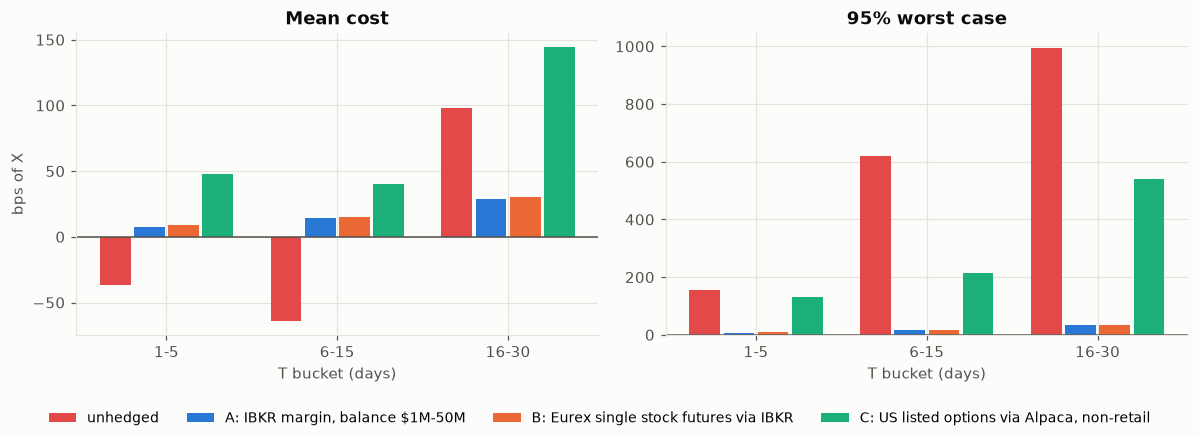

In [12]:
bt["T bucket"] = pd.cut(bt["T"], bins=[0, 5, 15, 30, 400], labels=["1-5", "6-15", "16-30", "> 30"])
kept = summary[summary["status"] == "kept"]
best = {}
for prefix in ("A | ", "B | ", "C | "):
    cand = kept[kept.index.str.startswith(prefix) & (kept["events"] >= 0.5 * len(bt))]
    if len(cand):
        best[prefix[0]] = cand["mean"].idxmin()
plot_cols = {"unhedged": "unhedged", **{f"{k}: {v[4:]}": v for k, v in best.items()}}

stats = bt.groupby("T bucket", observed=True)[list(plot_cols.values())].agg(["mean", lambda s: s.quantile(.95)])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
colors = [C["red"], C["blue"], C["orange"], C["aqua"]]
x = np.arange(len(stats.index))
width = 0.8 / len(plot_cols)
for i, ((label, col), color) in enumerate(zip(plot_cols.items(), colors)):
    axes[0].bar(x + i * width, stats[(col, "mean")], width=width - 0.02, color=color, label=label)
    axes[1].bar(x + i * width, stats[(col, stats.columns.levels[1][1])], width=width - 0.02, color=color, label=label)
for ax, title in zip(axes, ["Mean cost", "95% worst case"]):
    ax.set_xticks(x + width * (len(plot_cols) - 1) / 2, stats.index.astype(str))
    ax.set_title(title)
    ax.set_xlabel("T bucket (days)")
    ax.axhline(0, color=C["ink2"], linewidth=1)
axes[0].set_ylabel("bps of X")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), fontsize=9)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## 6. Hedge size and contract size

The formulas assume that the issuer can hedge any number of shares. Listed contracts have a fixed size (100 shares for options and standard futures, 10 for CME micro futures). The table shows $\Delta N = N \cdot D(1-w)/P_{\text{prev}}$ for each event and some values of $N$. If $\Delta N$ is small, the issuer has three options:

1. Over-hedge: round up to one contract.
2. Use a product without a fixed size: strategy A, perps, or total return futures.
3. Accept that fixed fees (for example the IBKR minimum of USD 1 for each order) become a large part of the cost.

In [13]:
dn_frac = usable["div_net_api"] / usable["p_prev"]       # Delta N / N
size_rows = []
for N in [10_000, 100_000, 1_000_000, 10_000_000]:
    dn = N * dn_frac
    size_rows.append({"N (shares)": f"{N:,}", "median Delta N": dn.median(), "share of events with Delta N < 10": (dn < 10).mean(),
                      "share with Delta N < 100": (dn < 100).mean()})
display(pd.DataFrame(size_rows).style.format({"median Delta N": "{:,.1f}", "share of events with Delta N < 10": "{:.0%}",
                                              "share with Delta N < 100": "{:.0%}"}))

,N (shares),median Delta N,share of events with Delta N < 10,share with Delta N < 100
0,"10,000",8.0,57%,100%
1,"100,000",79.9,0%,57%
2,"1,000,000",798.7,0%,0%
3,"10,000,000","7,986.5",0%,0%


## 7. Legal and operational limits

The full legal context is in [`doc/legal/`](doc/legal/README.md). The main limits for the three strategies are:

1. **Counterparty rule.** The Jersey FSC consent permits only regulated brokers and lenders. The regulator must be in the EU, Jersey, the UK, or a jurisdiction that is not on the FSC high-risk list. This rule excludes unregulated on-chain venues. See [`xstocks-issuer.md`](doc/legal/xstocks-issuer.md#counterparty-rule).
2. **No derivatives clause.** The prospectus does not permit the issuer to use futures or options for hedging. Strategies B and C can need a prospectus supplement, FSC consent, or a hedge by a group company. See [`xstocks-issuer.md`](doc/legal/xstocks-issuer.md#hedging-permission).
3. **Pledged shares.** The underlying shares are pledged to the security agent for the token holders. A loan for strategy A needs other collateral or no collateral. See [`xstocks-ecosystem.md`](doc/legal/xstocks-ecosystem.md#security-agent-and-collateral).
4. **Saxo is excluded.** Saxo stopped onboarding Jersey clients in 2024. See [`venues/saxo.md`](doc/legal/venues/saxo.md).
5. **Kraken xStocks perps are conditional.** A Bermuda entity books them. Bermuda must not be on the FSC high-risk list. The perp also references the issuer's own token outside US market hours. See [`venues/kraken-payward.md`](doc/legal/venues/kraken-payward.md).
6. **UNCONFIRMED values.** Check every UNCONFIRMED, ESTIMATE, and ASSUMPTION value in section 9 with the venue before a decision.

## 8. Result

The table gives two venues for each $T$ bucket: the venue with the lowest mean cost, and the venue with the lowest 95% worst case. Only venues with status **kept** are candidates. Section 5 gives the full numbers.

In [14]:
kept_cols = [c for c in summary.index if summary.loc[c, "status"] == "kept"]
result_rows = []
for bucket, grp in bt.groupby("T bucket", observed=True):
    cols = [c for c in kept_cols if grp[c].notna().mean() > 0.5]
    means, worst95 = grp[cols].mean(), grp[cols].quantile(0.95)
    result_rows.append({
        "T bucket (days)": bucket, "events": len(grp),
        "unhedged mean": grp["unhedged"].mean(), "unhedged 95% worst": grp["unhedged"].quantile(0.95),
        "lowest mean cost": means.idxmin(), "mean (bps)": means.min(),
        "lowest 95% worst case": worst95.idxmin(), "95% worst (bps)": worst95.min(),
    })
display(pd.DataFrame(result_rows).style.format({c: "{:.1f}" for c in ["unhedged mean", "unhedged 95% worst", "mean (bps)", "95% worst (bps)"]}))

,T bucket (days),events,unhedged mean,unhedged 95% worst,lowest mean cost,mean (bps),lowest 95% worst case,95% worst (bps)
0,1-5,2,-36.5,154.7,"A | IBKR margin, balance $1M-50M",7.3,"A | IBKR margin, balance $1M-50M",7.3
1,6-15,6,-64.2,619.8,"A | IBKR margin, balance $1M-50M",14.0,"A | IBKR margin, balance $1M-50M",15.7
2,16-30,6,97.9,994.9,"A | IBKR margin, balance $1M-50M",28.6,"A | IBKR margin, balance $1M-50M",33.4


**How to read the result.** The numbers below are from the run on 2026-10-19 (14 events, 7 stocks). The sample is small. Read the numbers as an indication, not as a statistic.

1. **The risk is real.** Unhedged, the mean result is close to zero, but the spread is large. The standard deviation is about 600 bps of $X$. The worst event (TSM, 22 days) cost about 1,100 bps of $X$. The 95% worst case grows with $T$.
2. **A and B cost about the same.** Both cost about 20 to 30 bps of $X$ on average and less than 50 bps in the 95% worst case. The cost grows linearly with $T$. The futures price contains a financing rate (SOFR + 0.81%) that is close to a margin loan rate (EFFR + 0.75% to 1.5%).
3. **C costs the most.** The mean is about 86 bps of $X$ and the 95% worst case is about 540 bps. The issuer pays for the option time value, and the volatility of these stocks is high (median 35%). In exchange, the issuer keeps the gain when the price goes down.
4. **The IBKR tier.** The cheapest row is the IBKR tier for $1M to $50M. This tier applies only when the loan is above $1M, so $N \cdot D \cdot 0.7 > 1{,}000{,}000$. For smaller loans, use the row for loans below $100k (about 3 bps more).
5. **Contract size.** For $N = 100{,}000$, more than half of the events need fewer than 100 shares. Options and standard futures then over-hedge. Strategy A has no contract size.
6. **Recommendation.** Strategy A is the cheapest and the easiest strategy under the current prospectus. It needs no derivatives. Its condition is a loan that does not use the pledged shares as collateral. Strategy B is an alternative of the same cost if the issuer gets permission to use derivatives.

## 9. Venues not in the tables

The tables in sections 4 to 8 keep only venues whose values are CONFIRMED. The venues below have at least one value that is UNCONFIRMED, an ESTIMATE, or an ASSUMPTION. They are not in the worked examples, the backtest, or the result.

To add a venue back, confirm its values with the venue, set its `check` to CONFIRMED in section 4, and run the notebook again.

In [15]:
other = pd.concat([
    venues_a_other.assign(strategy="A", value=venues_a_other["r_A_%_act360"].map("r_A {:.2f}%".format)),
    venues_b_other.assign(strategy="B", value=[f"r_B {r:.2f}%, f_B {f:.2f} bps"
                                               for r, f in zip(venues_b_other["r_B_%"], venues_b_other["f_B_bps_at_S_REF"])]),
    venues_c_other.assign(strategy="C", value=venues_c_other["f_C_bps_at_S_REF"].map("f_C {:.2f} bps".format)),
], ignore_index=True)
display(other[["strategy", "venue", "status", "check", "value", "note"]].style.hide(axis="index")
        .set_caption("Venues with values that are not CONFIRMED (f_B and f_C at a share price of 250 USD)"))

strategy,venue,status,check,value,note
A,"Swiss bank, institutional client",kept,ESTIMATE,r_A 4.88%,spread 1.00% ESTIMATE. Real terms depend on the bank and the client.
A,Payward intercompany loan,conditional,ASSUMPTION,r_A 4.88%,no public terms. Spread 1.00% ASSUMPTION. Needs a legal check.
A,Kraken spot margin (0.02% per 4 h),reference,UNCONFIRMED,r_A 43.20%,"rollover fee UNCONFIRMED. Too expensive, reference only."
A,Saxo margin (SOFR + 7%),excluded,UNCONFIRMED,r_A 10.88%,rate UNCONFIRMED. Saxo does not onboard Jersey clients.
B,CME single stock futures via IBKR,kept,UNCONFIRMED,"r_B 4.69%, f_B 0.92 bps",financing = ES implied financing (proxy). Exchange fee 0.30/side ASSUMPTION. IBKR access UNCONFIRMED.
B,Eurex equity total return futures,kept,ASSUMPTION,"r_B 4.38%, f_B 0.12 bps",traded spread 0.50% ASSUMPTION. Exchange fee 0.0006% of notional CONFIRMED. Broker fee not included.
B,"Kraken xStocks perps (PDSL, Bermuda)",conditional,ASSUMPTION,"r_B 10.95%, f_B 10.00 bps",funding 0.01% per 8 h = 10.95%/yr ASSUMPTION (no published history). Taker fee 0.05% UNCONFIRMED.
C,CME E-mini S&P 500 options via IBKR (SPYx only),kept,ASSUMPTION,f_C 0.22 bps,IBKR 0.85 CONFIRMED. Exchange fee 0.55 ASSUMPTION. Daily expiries.
